In [5]:
!pip install neo4j
!pip install pyvis
!pip install gdown
!pip -q install networkx matplotlib

In [6]:
import numpy as np
import gdown
import pandas as pd
from pyvis.network import Network
from IPython.display import HTML, display
from IPython.display import IFrame
from collections import defaultdict
from itertools import combinations
import networkx as nx
import matplotlib.pyplot as plt

In [7]:
gdown.download(id="1CsMLM8hhDiHwcfStHumUpjgUx7IbJORZ")

Downloading...
From: https://drive.google.com/uc?id=1CsMLM8hhDiHwcfStHumUpjgUx7IbJORZ
To: /content/events.csv
100%|██████████| 94.2M/94.2M [00:01<00:00, 68.1MB/s]


'events.csv'

In [8]:
CSV_PATH = "/content/events.csv"
df = pd.read_csv(CSV_PATH)
print("File yang digunakan:", CSV_PATH)

File yang digunakan: /content/events.csv


In [9]:
df.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [10]:
required = {"visitorid", "event", "itemid"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing}. Periksa file CSV.")

df["visitorid"] = pd.to_numeric(df["visitorid"], errors="coerce")
df["itemid"] = pd.to_numeric(df["itemid"], errors="coerce")
df["event"] = df["event"].astype("string").str.strip().str.lower()

before = len(df)
df = df.dropna(subset=["visitorid", "itemid", "event"]).copy()
df["visitorid"] = df["visitorid"].astype("int64")
df["itemid"] = df["itemid"].astype("int64")
df = df[df["event"].isin(["view", "addtocart", "transaction"])].copy()

print(f"Baris sebelum pembersihan: {before:,}")
print(f"Baris setelah pembersihan: {len(df):,}")
print("\nJumlah event:")
display(df["event"].value_counts().rename_axis("event").to_frame("jumlah"))

Baris sebelum pembersihan: 2,756,101
Baris setelah pembersihan: 2,756,101

Jumlah event:


,jumlah
event,
view,2664312
addtocart,69332
transaction,22457


In [11]:
summary = pd.DataFrame({
    "Metrik": [
        "Jumlah event",
        "Jumlah visitor unik",
        "Jumlah item unik",
        "Jumlah pasangan visitor-item unik",
        "Jumlah event view",
        "Jumlah event addtocart",
        "Jumlah event transaction",
    ],
    "Nilai": [
        len(df),
        df["visitorid"].nunique(),
        df["itemid"].nunique(),
        df[["visitorid", "itemid"]].drop_duplicates().shape[0],
        int((df["event"] == "view").sum()),
        int((df["event"] == "addtocart").sum()),
        int((df["event"] == "transaction").sum()),
    ]
})
display(summary)

,Metrik,Nilai
0,Jumlah event,2756101
1,Jumlah visitor unik,1407580
2,Jumlah item unik,235061
3,Jumlah pasangan visitor-item unik,2145179
4,Jumlah event view,2664312
5,Jumlah event addtocart,69332
6,Jumlah event transaction,22457


In [12]:
EVENT_WEIGHTS = {
    "view": 1,
    "addtocart": 3,
    "transaction": 5,
}

df["weight"] = df["event"].map(EVENT_WEIGHTS).astype("int8")

interactions = (
    df.assign(
        is_view=(df["event"] == "view").astype("int8"),
        is_cart=(df["event"] == "addtocart").astype("int8"),
        is_purchase=(df["event"] == "transaction").astype("int8"),
    )
    .groupby(["visitorid", "itemid"], as_index=False)
    .agg(
        score=("weight", "sum"),
        views=("is_view", "sum"),
        carts=("is_cart", "sum"),
        purchases=("is_purchase", "sum"),
        event_count=("event", "size"),
    )
)

print("Jumlah pasangan Visitor–Item:", f"{len(interactions):,}")
display(interactions.head())

Jumlah pasangan Visitor–Item: 2,145,179


,visitorid,itemid,score,views,carts,purchases,event_count
0,0,67045,1,1,0,0,1
1,0,285930,1,1,0,0,1
2,0,357564,1,1,0,0,1
3,1,72028,1,1,0,0,1
4,2,216305,2,2,0,0,2


In [13]:
MAX_EDGES = 250
MAX_VISITORS = 120
MAX_ITEMS = 80

item_popularity = interactions.groupby("itemid")["visitorid"].nunique().sort_values(ascending=False)
selected_items = set(item_popularity.head(MAX_ITEMS).index)

graph_df = interactions[interactions["itemid"].isin(selected_items)].copy()

visitor_activity = graph_df.groupby("visitorid")["itemid"].nunique().sort_values(ascending=False)
selected_visitors = set(visitor_activity.head(MAX_VISITORS).index)
graph_df = graph_df[graph_df["visitorid"].isin(selected_visitors)].head(MAX_EDGES)

net = Network(height="650px", width="100%", notebook=True, directed=False, bgcolor="#ffffff")
net.barnes_hut()

for row in graph_df.itertuples(index=False):
    v_node = f"Visitor {row.visitorid}"
    i_node = f"Item {row.itemid}"
    net.add_node(v_node, label=v_node, title=v_node, color="#4A90E2", group="Visitor")
    net.add_node(i_node, label=i_node, title=i_node, color="#F5A623", group="Item")
    net.add_edge(v_node, i_node, value=max(1, min(int(row.score), 10)),
                 title=f"score={row.score}; view={row.views}; cart={row.carts}; purchase={row.purchases}")

graph_path = "/content/rocket_retail_graph.html"
net.save_graph(graph_path)
print(f"Graph dibuat dari {len(graph_df):,} relasi sampel.")
display(IFrame(src=graph_path, width="100%", height=680))

Graph dibuat dari 250 relasi sampel.


In [14]:
top_items = (
    interactions.groupby("itemid")
    .agg(
        unique_visitors=("visitorid", "nunique"),
        total_score=("score", "sum"),
        total_views=("views", "sum"),
        total_carts=("carts", "sum"),
        total_purchases=("purchases", "sum"),
    )
    .sort_values(["unique_visitors", "total_score"], ascending=False)
    .head(10)
    .reset_index()
)
display(top_items)

,itemid,unique_visitors,total_score,total_views,total_carts,total_purchases
0,187946,2912,3416,3410,2,0
1,5411,2079,2352,2325,9,0
2,370653,1577,1854,1854,0,0
3,461686,1393,4122,2539,306,133
4,219512,1370,1944,1740,48,12
5,96924,1359,1633,1633,0,0
6,298009,1342,1642,1642,0,0
7,384302,1154,1798,1528,65,15
8,335975,1154,1428,1428,0,0
9,151444,1103,1230,1230,0,0


In [15]:
MIN_VISITORS_PER_ITEM = 5
MAX_CANDIDATE_ITEMS = 500

item_visitor_sets = (
    interactions.groupby("itemid")["visitorid"]
    .apply(set)
)

eligible_items = item_visitor_sets[
    item_visitor_sets.apply(len) >= MIN_VISITORS_PER_ITEM
]
eligible_items = eligible_items.loc[
    item_popularity[item_popularity.index.isin(eligible_items.index)]
    .head(MAX_CANDIDATE_ITEMS).index
]

visitor_to_items = defaultdict(list)
for item_id, visitors in eligible_items.items():
    for visitor_id in visitors:
        visitor_to_items[visitor_id].append(item_id)

shared_counts = defaultdict(int)
for items_for_visitor in visitor_to_items.values():
    if len(items_for_visitor) > 100:
        continue
    for a, b in combinations(sorted(items_for_visitor), 2):
        shared_counts[(a, b)] += 1

jaccard_rows = []
for (a, b), intersection in shared_counts.items():
    union = len(eligible_items[a]) + len(eligible_items[b]) - intersection
    if union:
        jaccard_rows.append((a, b, intersection, union, intersection / union))

jaccard_df = pd.DataFrame(
    jaccard_rows,
    columns=["item_a", "item_b", "shared_visitors", "union_visitors", "jaccard"]
)

if len(jaccard_df):
    jaccard_df = jaccard_df.sort_values(
        ["jaccard", "shared_visitors"], ascending=False
    ).reset_index(drop=True)
    display(jaccard_df.head(20))
else:
    print("Belum ada pasangan kandidat yang berbagi visitor. Coba turunkan MIN_VISITORS_PER_ITEM.")

,item_a,item_b,shared_visitors,union_visitors,jaccard
0,171878,218794,129,469,0.275053
1,38965,325310,108,446,0.242152
2,9877,241555,159,713,0.223001
3,241555,325310,125,571,0.218914
4,38965,241555,120,566,0.212014
5,9877,325310,125,615,0.203252
6,9877,38965,121,609,0.198686
7,268883,420960,111,600,0.185000
8,109618,243355,139,783,0.177522
9,218794,461686,256,1475,0.173559


In [16]:
def pearson_for_item_pair(item_a, item_b, min_overlap=3):
    a = interactions.loc[interactions["itemid"] == item_a, ["visitorid", "score"]]
    b = interactions.loc[interactions["itemid"] == item_b, ["visitorid", "score"]]
    merged = a.merge(b, on="visitorid", suffixes=("_a", "_b"))
    if len(merged) < min_overlap:
        return np.nan, len(merged)
    if merged["score_a"].nunique() < 2 or merged["score_b"].nunique() < 2:
        return np.nan, len(merged)
    return merged["score_a"].corr(merged["score_b"], method="pearson"), len(merged)

pearson_rows = []
if len(jaccard_df):
    for row in jaccard_df.head(200).itertuples(index=False):
        corr, overlap = pearson_for_item_pair(row.item_a, row.item_b, min_overlap=3)
        pearson_rows.append((row.item_a, row.item_b, corr, overlap, row.jaccard))

pearson_df = pd.DataFrame(
    pearson_rows,
    columns=["item_a", "item_b", "pearson", "shared_visitors", "jaccard"]
)
if len(pearson_df):
    display(pearson_df.sort_values("pearson", ascending=False, na_position="last").head(20))
else:
    print("Pearson belum dihitung karena belum tersedia kandidat pasangan.")

,item_a,item_b,pearson,shared_visitors,jaccard
35,266900,308438,0.782663,76,0.093317
55,355994,460188,0.767501,67,0.076037
127,69974,272770,0.761152,39,0.054930
132,16813,175356,0.743910,37,0.053712
87,84160,370653,0.707271,139,0.063967
168,22436,299038,0.695185,31,0.048362
101,22436,339703,0.673892,50,0.059976
69,244252,299677,0.667167,42,0.068966
194,188051,455183,0.664034,43,0.045161
76,183511,441852,0.626290,61,0.067416


In [23]:
def recommend_items(visitor_id, top_n=10, similarity_df=None, similarity_col="jaccard"):
    if similarity_df is None:
        similarity_df = jaccard_df

    if similarity_df.empty:
        return pd.DataFrame(columns=["itemid", "recommendation_score"])

    history = interactions.loc[
        interactions["visitorid"] == visitor_id, ["itemid", "score"]
    ]
    if history.empty:
        return pd.DataFrame(columns=["itemid", "recommendation_score"])

    seen_items = set(history["itemid"])
    history_scores = dict(zip(history["itemid"], history["score"]))

    candidate_scores = defaultdict(float)
    for row in similarity_df.itertuples(index=False):
        sim = getattr(row, similarity_col, np.nan)
        if pd.isna(sim) or sim <= 0:
            continue
        a, b = row.item_a, row.item_b
        if a in seen_items and b not in seen_items:
            candidate_scores[b] += float(sim) * history_scores.get(a, 1)
        elif b in seen_items and a not in seen_items:
            candidate_scores[a] += float(sim) * history_scores.get(b, 1)

    return (
        pd.DataFrame(candidate_scores.items(), columns=["itemid", "recommendation_score"])
        .sort_values("recommendation_score", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )

visitor_item_counts = interactions.groupby("visitorid")["itemid"].nunique()
example_candidates = visitor_item_counts[visitor_item_counts >= 2]
if len(example_candidates) and len(jaccard_df):
    example_visitor = int(example_candidates.index[0])
    print("Contoh visitor:", example_visitor)
    print("Riwayat item:")
    display(interactions.loc[interactions["visitorid"] == example_visitor].head(10))
    print("Rekomendasi:")
    display(recommend_items(example_visitor, top_n=10))
else:
    print("Belum cukup kandidat untuk menghasilkan rekomendasi. Jalankan sel Jaccard dan pastikan hasilnya tidak kosong.")

Contoh visitor: 0
Riwayat item:


,visitorid,itemid,score,views,carts,purchases,event_count
0,0,67045,1,1,0,0,1
1,0,285930,1,1,0,0,1
2,0,357564,1,1,0,0,1


Rekomendasi:


,itemid,recommendation_score
0,365673,0.010121
1,227211,0.008299
2,240262,0.006073
3,409804,0.004292
4,213834,0.003992
5,143416,0.003861
6,380237,0.003788
7,396491,0.003704
8,299222,0.002611
9,30024,0.002114


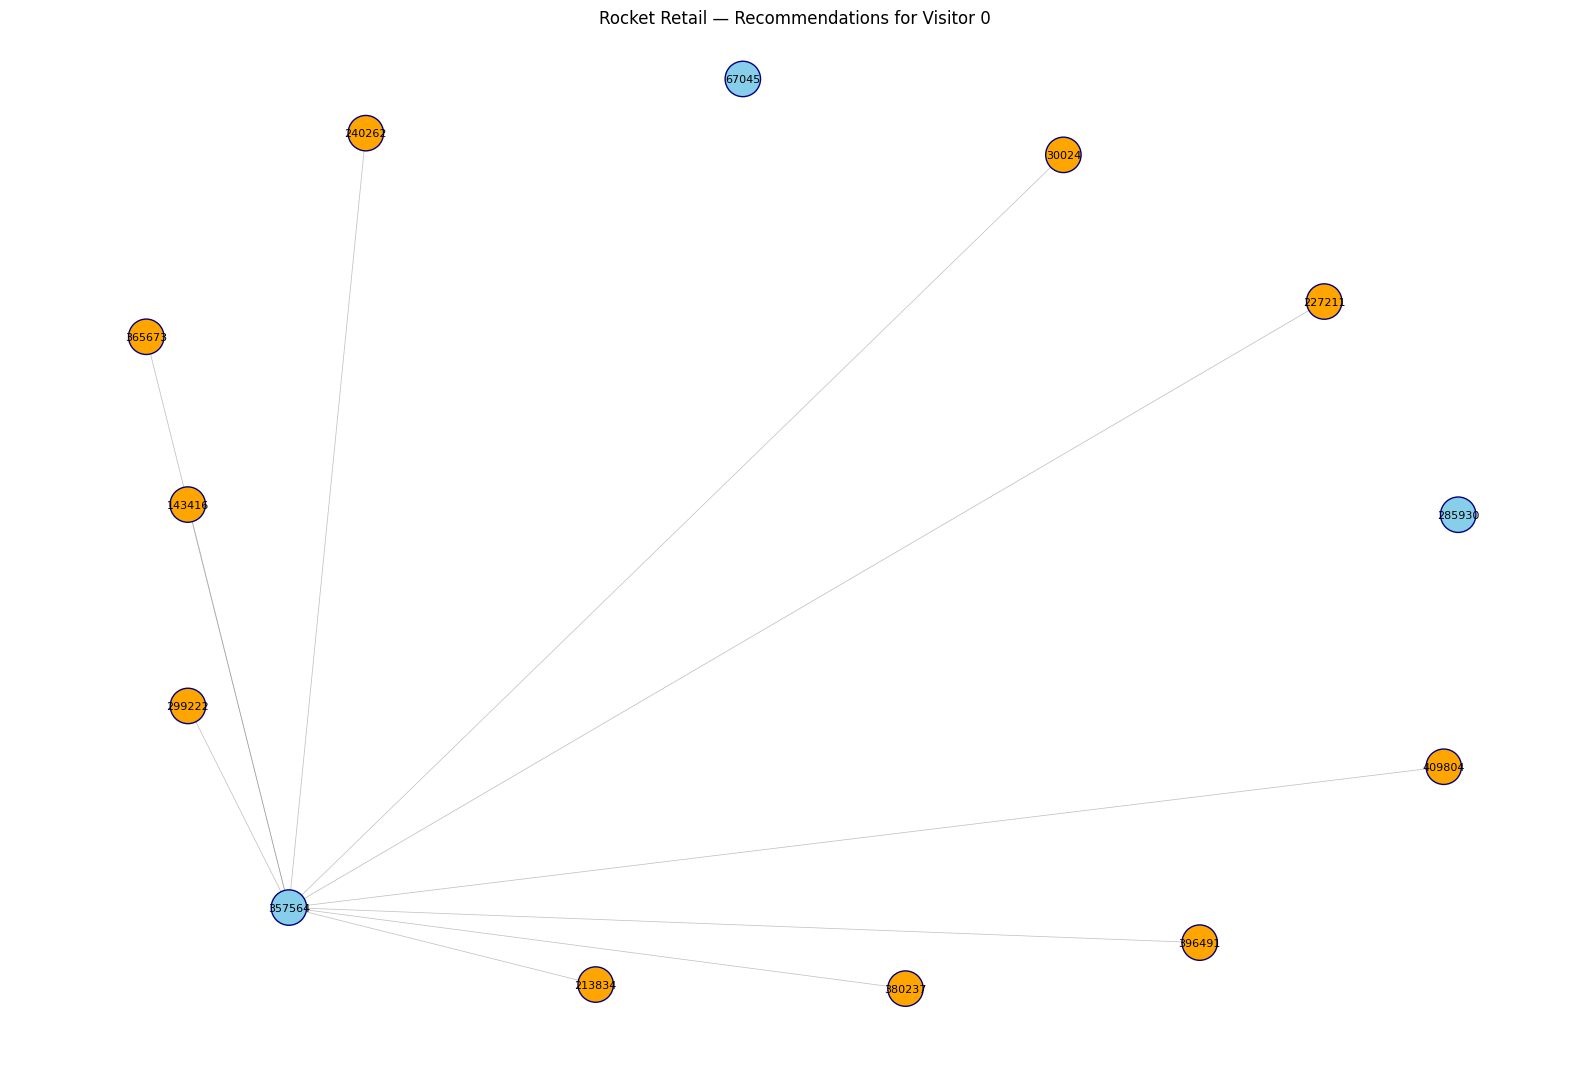

In [24]:
visitor_id = example_visitor # VISITOR 0 TADI
top_n = 10

history = interactions.loc[
    interactions["visitorid"] == visitor_id,
    ["itemid", "score"]
].drop_duplicates(subset="itemid")

recommendations = recommend_items(
    visitor_id,
    top_n=top_n,
    similarity_df=jaccard_df,
    similarity_col="jaccard"
)

if recommendations.empty:
    print("Tidak ada rekomendasi untuk visitor ini.")

else:
    G = nx.Graph()

    history_items = set(history["itemid"])
    recommended_items = set(recommendations["itemid"])

    for row in history.itertuples(index=False):
        G.add_node(
            int(row.itemid),
            node_type="history",
            score=float(row.score)
        )

    for row in recommendations.itertuples(index=False):
        G.add_node(
            int(row.itemid),
            node_type="recommended",
            score=float(row.recommendation_score)
        )

    similarity_lookup = {}

    for row in jaccard_df.itertuples(index=False):
        a, b = int(row.item_a), int(row.item_b)
        similarity_lookup[(min(a, b), max(a, b))] = float(row.jaccard)

    for source in history_items:
        for target in recommended_items:
            key = (min(int(source), int(target)),
                   max(int(source), int(target)))

            sim = similarity_lookup.get(key, 0)

            if sim > 0:
                G.add_edge(
                    int(source),
                    int(target),
                    weight=sim
                )

    pos = nx.spring_layout(
        G,
        seed=42,
        weight="weight",
        k=0.8
    )

    plt.figure(figsize=(16, 11))

    node_colors = [
        "skyblue" if G.nodes[n]["node_type"] == "history"
        else "orange"
        for n in G.nodes()
    ]

    edge_widths = [
        0.5 + 5 * G[u][v]["weight"]
        for u, v in G.edges()
    ]

    nx.draw_networkx_edges(
        G, pos,
        width=edge_widths,
        alpha=0.5,
        edge_color="gray"
    )

    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        node_size=650,
        edgecolors="navy"
    )

    nx.draw_networkx_labels(
        G, pos,
        font_size=8
    )

    plt.title(
        f"Rocket Retail — Recommendations for Visitor {visitor_id}"
    )
    plt.axis("off")
    plt.tight_layout()
    plt.show()
